In [1]:
# Librerie
import pandas as pd
import numpy as np
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.decomposition import PCA

# High Dimensionality
from pyod.models.abod import ABOD

# Elliptic
from sklearn.covariance import EllipticEnvelope

# RKNN
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

# Grafici
import matplotlib.pyplot as plt
import seaborn as sns

# Proiezioni
from sklearn.manifold import MDS
from sklearn.manifold import TSNE
import umap

In [2]:
# Dati
df = pd.read_csv("df.csv")

train = pd.read_csv("train_imputed.csv")
test = pd.read_csv("test_imputed.csv")

tt = np.concatenate([train, test], axis=0)
df_unito = pd.DataFrame(tt, columns=train.columns)

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_47800/4040832297.py:2: DtypeWarning: Columns (53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("df.csv")


In [3]:
# Scalers

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X = df_unito.values
y = np.array(df_unito['sii'])
X_standard = standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(
    X_standard, y, test_size=0.3, random_state=0)

In [5]:
# Dataset Outliers
df_outliers = pd.read_csv("df_outliers.csv")

df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod'] == 1).astype(int)
)

df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)
# volendo aumentare a 2% per maggioranza


In [6]:
%%time
#PCA
pca = PCA(n_components=3, random_state=222)
df_unito_pca = pca.fit_transform(X_standard)

CPU times: user 3.81 ms, sys: 2.31 ms, total: 6.11 ms
Wall time: 3.97 ms


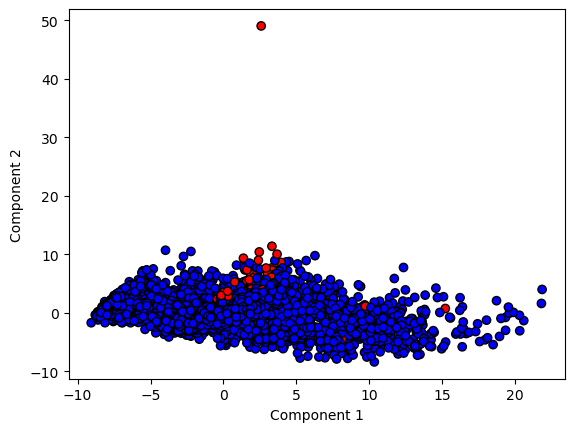

In [10]:
# 2D
fig, ax= plt.subplots()
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

import plotly.express as px

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_pca[:, 0],
    'Component 2': df_unito_pca[:, 1],
    'Component 3': df_unito_pca[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot, 
    x='Component 1', 
    y='Component 2', 
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Viridis', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()



In [11]:
%%time
#UMAP
umappe = umap.UMAP(n_components = 3, random_state = 222)
df_unito_umap = umappe.fit_transform(X_standard)

/opt/anaconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



CPU times: user 15.2 s, sys: 1.14 s, total: 16.4 s
Wall time: 13.5 s


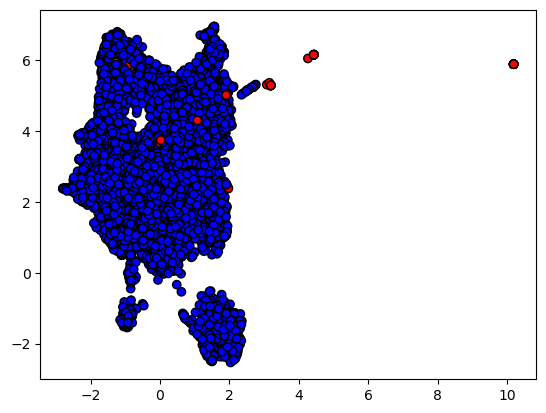

In [16]:
# 2D

plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

#ax.set_xlabel('Component 1')
#ax.set_ylabel('Component 2')

plt.show()
import plotly.express as px
import pandas as pd

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_umap[:, 0],
    'Component 2': df_unito_umap[:, 1],
    'Component 3': df_unito_umap[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot, 
    x='Component 1', 
    y='Component 2', 
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()
